# BS49903 · DS/AI for Biology
## Week 10 Practice Notebook — Image Filtering

Covers Week 10 (sliding windows and kernels, mean and Gaussian smoothing, median filter,
Sobel edge detection, template matching, correlation vs. convolution).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal
from skimage import data

def show(img, title="", ax=None, cmap="gray", **kw):
    ax = ax or plt.gca()
    ax.imshow(img, cmap=cmap, **kw)
    ax.set_title(title); ax.axis("off")

rng = np.random.default_rng(0)

---
# Part 1 · A neighborhood operation: g[i, j] = F(window around f[i, j])

### 1.1 The 6 × 6 example from the lecture

In [2]:
f = np.array([[52, 58,  60,  62, 67, 70],
              [55, 59,  61,  63, 66, 72],
              [57, 120, 118, 125, 68, 74],
              [60, 122, 130, 121, 70, 76],
              [62, 119, 124, 117, 72, 78],
              [64, 66,  68,  70, 74, 80]])

window = f[2:5, 1:4]              # 3 x 3 neighborhood around f[3, 2] = 130
print(window)
print("mean of the window:", window.mean())

[[120 118 125]
 [122 130 121]
 [119 124 117]]
mean of the window: 121.77777777777777


### 1.2 Slide the window over every pixel

`np.pad` adds `k` pixels around the border so the window always fits. With `mode="edge"` the
border pixels are repeated.

In [3]:
def correlate2d(f, w):
    k = w.shape[0] // 2
    fp = np.pad(f.astype(float), k, mode="edge")
    g = np.zeros_like(f, dtype=float)
    for i in range(f.shape[0]):
        for j in range(f.shape[1]):
            window = fp[i:i + 2*k + 1, j:j + 2*k + 1]
            g[i, j] = np.sum(window * w)
    return g

box = np.ones((3, 3)) / 9         # box kernel (mean filter)
identity = np.zeros((3, 3)); identity[1, 1] = 1

print(np.round(correlate2d(f, box), 1))
print("identity kernel returns f:", np.allclose(correlate2d(f, identity), f))

[[ 54.8  57.2  60.3  63.1  66.6  69.3]
 [ 62.8  71.1  80.7  76.7  74.1  70.3]
 [ 71.7  86.9 102.1  91.3  81.7  72. ]
 [ 79.9 101.3 121.8 105.   89.   74. ]
 [ 75.4  90.6 104.1  94.   84.2  76. ]
 [ 70.1  77.9  85.3  81.9  79.4  77.3]]
identity kernel returns f: True


The loop is slow. `scipy.ndimage.correlate` does the same computation (`mode="nearest"` is the
same as `"edge"` padding), so we use it from here on.

In [4]:
print(np.allclose(correlate2d(f, box), ndimage.correlate(f.astype(float), box, mode="nearest")))

True


---
# Part 2 · Smoothing: mean and Gaussian filters

We crop the cell from `data.cell()` and add Gaussian noise.

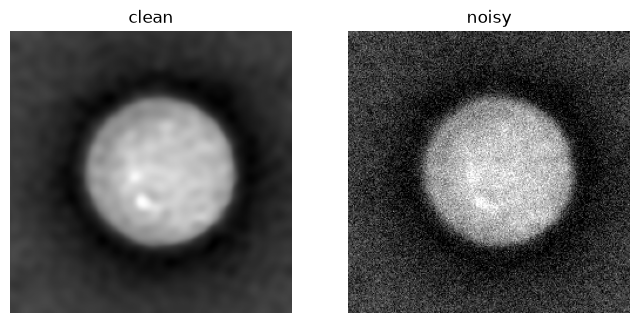

In [5]:
clean = data.cell()[255:495, 300:540].astype(float)          # 240 x 240 crop around the cell
noisy = clean + rng.normal(0, 25, clean.shape)               # noise std = 25

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
show(clean, "clean", ax[0], vmin=0, vmax=255); show(noisy, "noisy", ax[1], vmin=0, vmax=255)
plt.show()

### 2.1 Mean filter: a larger window removes more noise, but blurs edges

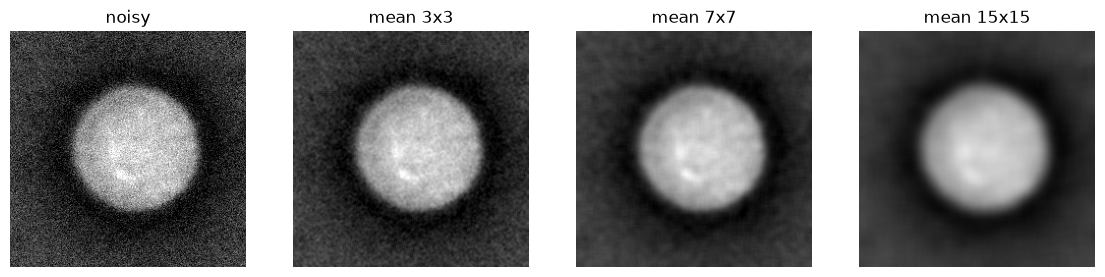

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
show(noisy, "noisy", ax[0], vmin=0, vmax=255)
for a, n in zip(ax[1:], [3, 7, 15]):
    show(ndimage.uniform_filter(noisy, size=n), f"mean {n}x{n}", a, vmin=0, vmax=255)
plt.show()

### 2.2 Gaussian filter: nearby pixels get larger weights

w[u, v] = exp(−(u² + v²) / 2σ²), normalized so the weights sum to 1.

In [7]:
sigma, k = 1.0, 3
u = np.arange(-k, k + 1)
U, V = np.meshgrid(u, u, indexing="ij")
w = np.exp(-(U**2 + V**2) / (2 * sigma**2))
w /= w.sum()
print(np.round(w, 2))
print("sum:", w.sum())

[[0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.01 0.02 0.01 0.   0.  ]
 [0.   0.01 0.06 0.1  0.06 0.01 0.  ]
 [0.   0.02 0.1  0.16 0.1  0.02 0.  ]
 [0.   0.01 0.06 0.1  0.06 0.01 0.  ]
 [0.   0.   0.01 0.02 0.01 0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.  ]]
sum: 1.0


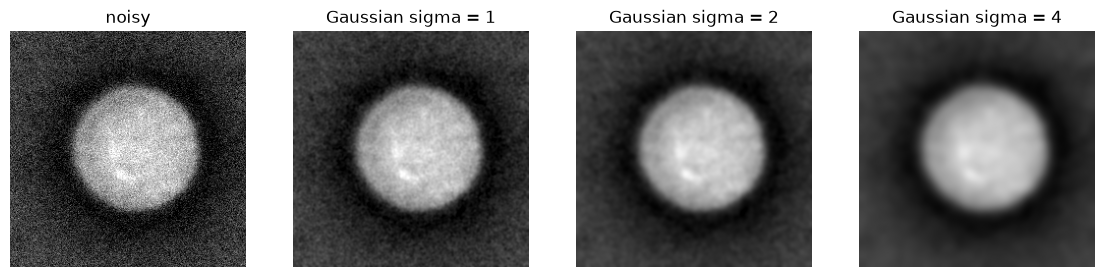

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
show(noisy, "noisy", ax[0], vmin=0, vmax=255)
for a, s in zip(ax[1:], [1, 2, 4]):
    show(ndimage.gaussian_filter(noisy, sigma=s), f"Gaussian sigma = {s}", a, vmin=0, vmax=255)
plt.show()

σ is in pixels: structures smaller than about σ are smoothed away. Choose σ smaller than the
structure you want to keep and larger than the noise.

---
# Part 3 · Median filter for salt-and-pepper noise

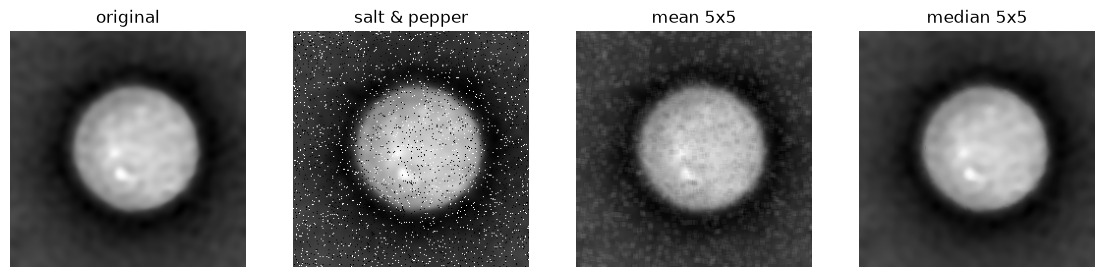

mean   5x5: mean abs error vs. original = 6.4
median 5x5: mean abs error vs. original = 0.4


In [9]:
sp = clean.copy()
mask = rng.random(clean.shape)
sp[mask < 0.03] = 0               # pepper
sp[mask > 0.97] = 255             # salt

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
show(clean, "original", ax[0], vmin=0, vmax=255)
show(sp, "salt & pepper", ax[1], vmin=0, vmax=255)
show(ndimage.uniform_filter(sp, size=5), "mean 5x5", ax[2], vmin=0, vmax=255)
show(ndimage.median_filter(sp, size=5), "median 5x5", ax[3], vmin=0, vmax=255)
plt.show()

for name, out in [("mean", ndimage.uniform_filter(sp, size=5)), ("median", ndimage.median_filter(sp, size=5))]:
    print(f"{name:6s} 5x5: mean abs error vs. original = {np.abs(out - clean).mean():.1f}")

The mean spreads each outlier over its window. The median ignores it, because an outlier is
never the middle value.

---
# Part 4 · Sobel filter: edge detection

### 4.1 Gx and Gy

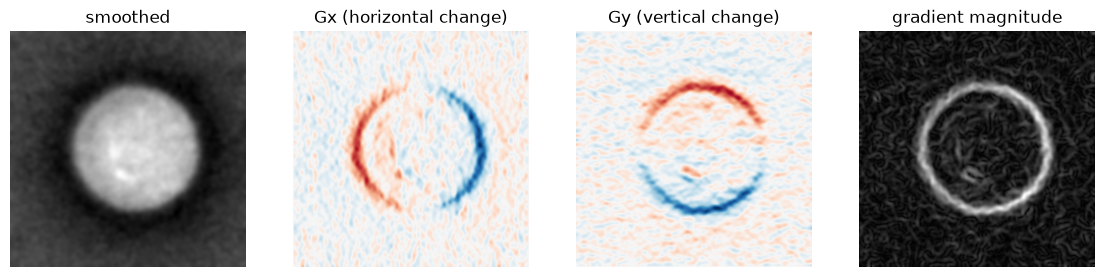

In [10]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])           # horizontal change -> vertical edges
sobel_y = sobel_x.T                         # vertical change -> horizontal edges

img = ndimage.gaussian_filter(noisy, 2)     # smooth first, otherwise Sobel amplifies the noise
Gx = ndimage.correlate(img, sobel_x)
Gy = ndimage.correlate(img, sobel_y)
mag = np.sqrt(Gx**2 + Gy**2)                # gradient magnitude |∇f|

lim = np.abs(Gx).max()
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
show(img, "smoothed", ax[0])
show(Gx, "Gx (horizontal change)", ax[1], cmap="RdBu_r", vmin=-lim, vmax=lim)
show(Gy, "Gy (vertical change)", ax[2], cmap="RdBu_r", vmin=-lim, vmax=lim)
show(mag, "gradient magnitude", ax[3])
plt.show()

Red is dark → bright, blue is bright → dark, moving right (Gx) or down (Gy). Where on the cell
boundary is Gx close to 0, and why?

---
# Part 5 · Template matching: the kernel is an image patch

Use a patch of the clean cell as the kernel and slide it over the noisy, larger image. The
response is highest where the image looks most like the patch. We subtract the means first,
so a bright background alone does not give a high response.

best match centered at (row, col): (375, 416)


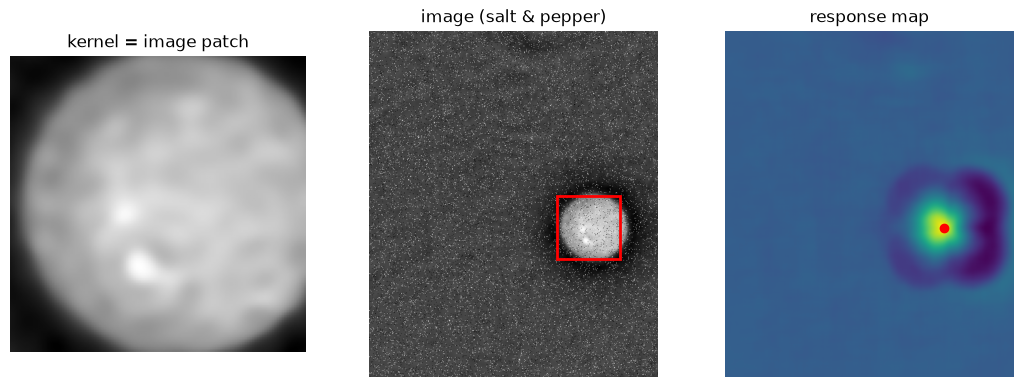

In [11]:
template = clean[60:180, 60:180]                    # 120 x 120 patch: the cell itself
big = data.cell().astype(float)
big_sp = big.copy()
m = rng.random(big.shape)
big_sp[m < 0.03] = 0; big_sp[m > 0.97] = 255

t = template - template.mean()
response = signal.correlate(big_sp - big_sp.mean(), t, mode="same", method="fft")   # same operation, FFT for speed
i, j = np.unravel_index(np.argmax(response), response.shape)
print("best match centered at (row, col):", (int(i), int(j)))

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
show(template, "kernel = image patch", ax[0])
show(big_sp, "image (salt & pepper)", ax[1])
ax[1].add_patch(plt.Rectangle((j - 60, i - 60), 120, 120, fill=False, ec="red", lw=2))
show(response, "response map", ax[2], cmap="viridis")
ax[2].plot(j, i, "r.", ms=12)
plt.show()